### Week 7 - task
- student name : chanin jung (AI specialization)
- neptun code : Z5XBZP

### Assignment: Decision Trees + Naive Bayes Classification + Model Comparison

- **Dataset:** the **same labelled** tabular dataset as Week 4 (PCA), Week 5 (DBSCAN + Hierarchical) and Week 6 (K-means) - the Kaggle *Spotify Tracks Dataset* (local copy `spotify_data.csv`). It is labelled, so it can be reused for supervised classification: the label is `track_genre` (8 genres).
- **Task type:** supervised learning (multi-class classification, 8 classes).
- **Submission:** this notebook - code, plots, tables and short written answers.

#### Constraints (all satisfied below)
- The same cleaned dataset is used throughout the whole notebook.
- `X` = the 15 numeric audio features, `y` = `track_genre`.
- Proper train / validation / test workflow (stratified).
- A `Pipeline` is used wherever preprocessing is needed.
- Categorical variables are encoded (`explicit` -> 0/1).
- Scaling is discussed and tested (it is **not** required for trees or Naive Bayes).
- The comparison includes **Decision Tree** and **Naive Bayes** with the *same* validation criteria.

#### Structure
- **Part A** - setup + data preparation (X, y, splits, shared metrics)
- **Part B** - Decision Tree (B1 initial model, B2 complexity control, B3 interpretation)
- **Part C** - Naive Bayes (C1 variant choice, C2 fit + preprocessing experiments, C3 independence assumption)
- **Part D** - final comparison of the two models
- **Part E** - final prediction check + recommendation

### Consistency with the previous assignments
Part A below is the **same cleaning and the same 3,000-track subsample as Week 5/6**, so the `X` matrix is directly comparable with the clustering notebooks. The only change is that `track_genre`, which was kept "for interpretation only" in the unsupervised tasks, now becomes the supervised target `y`.

| Step | Week 4/5/6 (reused here unchanged) |
|---|---|
| Raw file | `spotify_data.csv` (latin-1), BOM stripped, `Unnamed: 0` dropped |
| Text / ID columns | `track_id`, `artists`, `album_name`, `track_name` dropped |
| Categorical encoding | `explicit` (bool) -> 0/1; it is the only categorical column |
| Rows kept | the same 8 balanced genres -> 8,000 tracks, 0 missing values |
| Features (`X`) | the same 15 numeric features |
| Sample | the same stratified subsample: 375 tracks per genre -> **3,000 tracks** (`RandomState(42)`) |
| Target (`y`) | `track_genre` (8 classes) - **now used as the supervised label** |

### Part A: Setup + Data Preparation

In [1]:
# ==========================================
# Part A: Setup + Data Preparation
# (identical cleaning code to Week 5/6 - same dataset, same features, same rows)
# ==========================================
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB, CategoricalNB, MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1) Load the dataset (same loader as Week 4/5/6: local copy -> works offline)
df = pd.read_csv("spotify_data.csv", encoding="latin-1")
df.columns = [c.replace("\ufeff", "").replace("\u00ef\u00bb\u00bf", "") for c in df.columns]
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
print("Raw shape:", df.shape)

# 2) Drop textual / ID columns (no textual data used)
df = df.drop(columns=["track_id", "artists", "album_name", "track_name"])

# 3) Encode the only categorical variable: explicit (bool -> 0/1)
df["explicit"] = df["explicit"].astype(int)

# 4) Keep the same 8 balanced genres as Week 4/5/6
GENRES = ["acoustic", "classical", "country", "edm",
          "heavy-metal", "hip-hop", "jazz", "reggae"]
df = df[df["track_genre"].isin(GENRES)].copy()
print("Rows after genre filter:", len(df), "| Columns:", df.shape[1])

# 5) Handle missing values if necessary
missing = df.isnull().sum()
print("Total missing values:", int(missing.sum()))
if int(missing.sum()) > 0:
    df = df.dropna().reset_index(drop=True)
    print("Rows after dropping NaN:", len(df))
else:
    print("-> No missing values, no imputation needed.")

# 6) y = target class (the genre label) ; X = numeric feature matrix
y_all = df["track_genre"].reset_index(drop=True)
X_all = df.drop(columns=["track_genre"]).reset_index(drop=True)
print("\nX shape:", X_all.shape)
print("Features:", list(X_all.columns))
print("All features numeric:", all(pd.api.types.is_numeric_dtype(t) for t in X_all.dtypes))

Raw shape: (114000, 20)
Rows after genre filter: 8000 | Columns: 16
Total missing values: 0
-> No missing values, no imputation needed.

X shape: (8000, 15)
Features: ['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
All features numeric: True


**Why these features are appropriate.** The 15 features are the audio descriptors of each track (how loud, danceable, energetic, acoustic, instrumental it is, plus `tempo`, `key`, `mode`, `time_signature`, `explicit`). Genres differ exactly along these axes (e.g. classical tracks are acoustic and instrumental, edm tracks are loud and energetic), so they form a natural, information-rich feature set for predicting `track_genre`.

**Is scaling needed?** No. `DecisionTreeClassifier` splits on thresholds of single features and `GaussianNB` models each feature independently with its own mean/variance, so both are **invariant to monotonic rescaling** - scaling would not change their predictions. We still test a scaled `GaussianNB` in Part C to *demonstrate* this, and we keep every preprocessing step inside a `Pipeline` (as the assignment requires) so that no information leaks from the validation/test sets into training.

**Irrelevant / redundant features.** `key`, `mode` and `time_signature` are nominal-ish integers (a key of 1 is not "less than" a key of 2) and are weak genre signals; `duration_ms` is on a very different scale and only mildly informative. They are kept in the main model, but the Naive Bayes experiments in Part C test a reduced feature subset.

In [2]:
# 7) Same reproducible stratified subsample as Week 5/6: 375 tracks per genre -> 3,000
rng = np.random.RandomState(RANDOM_STATE)
PER_GENRE = 375
idx = np.sort(np.concatenate([
    rng.choice(np.where(y_all.values == g)[0], PER_GENRE, replace=False) for g in GENRES
]))
X = X_all.iloc[idx].reset_index(drop=True)
y = y_all.iloc[idx].reset_index(drop=True)
print("Classification sample:", X.shape)
print(y.value_counts().sort_index().to_string())

# 8) Stratified train / validation / test split: 60% (1800) - 20% (600) - 20% (600)
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)

print("\ntrain:", X_train.shape, "| validation:", X_val.shape, "| test:", X_test.shape)
print("\nClass balance (train):")
print(y_train.value_counts().sort_index().to_string())

Classification sample: (3000, 15)
track_genre
acoustic       375
classical      375
country        375
edm            375
heavy-metal    375
hip-hop        375
jazz           375
reggae         375

train: (1800, 15) | validation: (600, 15) | test: (600, 15)

Class balance (train):
track_genre
acoustic       225
classical      225
country        225
edm            225
heavy-metal    225
hip-hop        225
jazz           225
reggae         225


**Split rationale.** We use a **60 / 20 / 20** stratified split: the model is fitted on `X_train`, every candidate configuration is compared on `X_val` (this is the *only* set used for model selection), and `X_test` is touched **once**, at the very end, to report the final unbiased performance. Stratification keeps all 8 genres equally represented (225 / 75 / 75 tracks per genre) in every split.

### The validation criteria (used identically for both models)

Multi-class problem with balanced classes, so **macro-averaged** scores are the natural choice (each of the 8 genres counts equally):

| Criterion | Direction | What it rewards |
|---|---|---|
| Accuracy | higher is better | overall fraction of correct predictions |
| Precision (macro) | higher is better | per class, of the tracks predicted as genre *g*, how many really are *g* |
| Recall (macro) | higher is better | per class, of the real genre-*g* tracks, how many were found |
| F1-score (macro) | higher is better | harmonic mean of precision and recall |

We also report a **confusion matrix** for the final models, and a 5-fold cross-validation macro-F1 on the training set as a robustness check.

In [3]:
# 9) ONE shared metric helper -> the SAME criteria for BOTH model families
def metrics(y_true, y_pred):
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision_macro": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "recall_macro": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "f1_macro": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
    }


def report_row(name, y_true, y_pred):
    m = metrics(y_true, y_pred)
    m = {"model": name, **m}
    return m


print("metrics() helper ready: accuracy, macro precision, macro recall, macro F1")

metrics() helper ready: accuracy, macro precision, macro recall, macro F1


### Part B: Decision Tree Classification

#### B1. Initial Decision Tree model
Baseline: scikit-learn defaults (Gini impurity, no depth limit). An unpruned tree normally fits the training data almost perfectly, which we expect to be **overfitting**.

In [4]:
# ----- B1: initial Decision Tree (baseline configuration) -----
dt_init = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_init.fit(X_train, y_train)

print("Parameters (baseline):")
print("  criterion      :", dt_init.criterion)
print("  max_depth      :", dt_init.max_depth, "(None = unlimited)")
print("  min_samples_split:", dt_init.min_samples_split)
print("  min_samples_leaf :", dt_init.min_samples_leaf)
print("  ccp_alpha      :", dt_init.ccp_alpha)
print()
print("Tree depth       :", dt_init.get_depth())
print("Number of leaves :", dt_init.get_n_leaves())
print("Number of nodes  :", dt_init.tree_.node_count)

b1 = pd.DataFrame([
    report_row("DT baseline (train)", y_train, dt_init.predict(X_train)),
    report_row("DT baseline (validation)", y_val, dt_init.predict(X_val)),
])
display(b1)

Parameters (baseline):
  criterion      : gini
  max_depth      : None (None = unlimited)
  min_samples_split: 2
  min_samples_leaf : 1
  ccp_alpha      : 0.0

Tree depth       : 20
Number of leaves : 394
Number of nodes  : 787


,model,accuracy,precision_macro,recall_macro,f1_macro
0,DT baseline (train),0.9972,0.9972,0.9972,0.9972
1,DT baseline (validation),0.6417,0.6392,0.6417,0.6397


#### B2. Controlling tree complexity
We compare **9 configurations**, changing `max_depth`, `min_samples_split`, `min_samples_leaf` and `ccp_alpha` one family at a time, and record depth, leaves and the four criteria on the validation set. The **only** selection criterion is validation performance (macro-F1, tie-broken by validation accuracy).

In [5]:
# ----- B2: at least 4 different Decision Tree configurations -----
configs = {
    "default (no limit)":   DecisionTreeClassifier(random_state=RANDOM_STATE),
    "max_depth=2":          DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
    "max_depth=3":          DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "max_depth=5":          DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "max_depth=8":          DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    "min_samples_split=50": DecisionTreeClassifier(min_samples_split=50, random_state=RANDOM_STATE),
    "min_samples_leaf=20":  DecisionTreeClassifier(min_samples_leaf=20, random_state=RANDOM_STATE),
    "ccp_alpha=0.001":      DecisionTreeClassifier(ccp_alpha=0.001, random_state=RANDOM_STATE),
    "ccp_alpha=0.005":      DecisionTreeClassifier(ccp_alpha=0.005, random_state=RANDOM_STATE),
}

rows = []
for name, clf in configs.items():
    clf.fit(X_train, y_train)
    tr = metrics(y_train, clf.predict(X_train))
    va = metrics(y_val, clf.predict(X_val))
    rows.append({
        "configuration": name,
        "depth": clf.get_depth(),
        "leaves": clf.get_n_leaves(),
        "train_acc": tr["accuracy"],
        "val_acc": va["accuracy"],
        "val_prec": va["precision_macro"],
        "val_rec": va["recall_macro"],
        "val_f1": va["f1_macro"],
    })

dt_results = pd.DataFrame(rows).sort_values("val_f1", ascending=False).reset_index(drop=True)
display(dt_results)

,configuration,depth,leaves,train_acc,val_acc,val_prec,val_rec,val_f1
0,max_depth=8,8,100,0.7833,0.6550,0.6653,0.6550,0.6542
1,ccp_alpha=0.001,15,198,0.9078,0.6500,0.6471,0.6500,0.6469
2,default (no limit),20,394,0.9972,0.6417,0.6392,0.6417,0.6397
3,min_samples_split=50,17,79,0.7172,0.6233,0.6377,0.6233,0.6230
4,min_samples_leaf=20,10,63,0.7000,0.6250,0.6269,0.6250,0.6213
5,ccp_alpha=0.005,8,24,0.6544,0.6017,0.6262,0.6017,0.6025
6,max_depth=5,5,27,0.5961,0.5483,0.5853,0.5483,0.5601
7,max_depth=3,3,8,0.4156,0.3900,0.3231,0.3900,0.3001
8,max_depth=2,2,4,0.3161,0.3017,0.3092,0.3017,0.2445


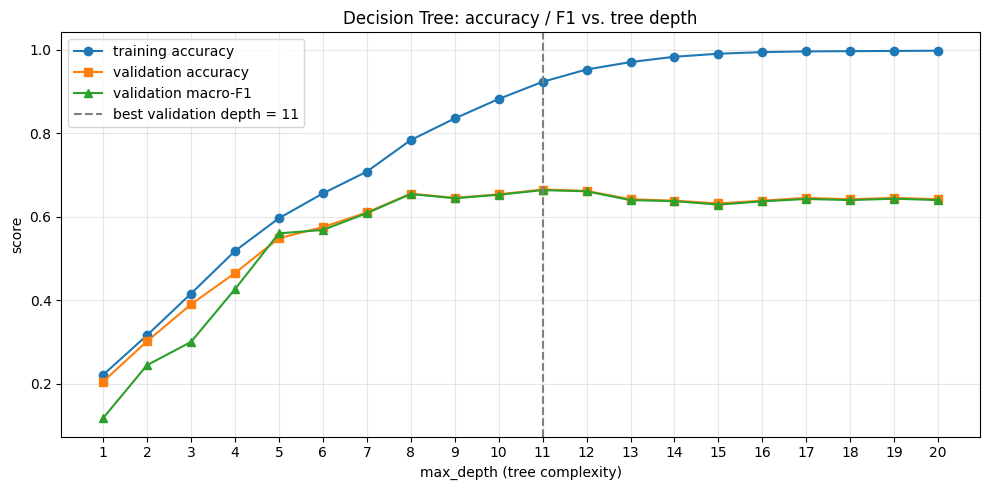

In [6]:
# ----- B2 plot: how does performance change with tree depth (complexity)? -----
depths = list(range(1, 21))
train_accs, val_accs, val_f1s = [], [], []
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, clf.predict(X_train)))
    val_accs.append(accuracy_score(y_val, clf.predict(X_val)))
    val_f1s.append(f1_score(y_val, clf.predict(X_val), average="macro", zero_division=0))

best_depth = depths[int(np.argmax(val_f1s))]
plt.figure(figsize=(10, 5))
plt.plot(depths, train_accs, marker="o", label="training accuracy")
plt.plot(depths, val_accs, marker="s", label="validation accuracy")
plt.plot(depths, val_f1s, marker="^", label="validation macro-F1")
plt.axvline(best_depth, color="grey", linestyle="--",
            label=f"best validation depth = {best_depth}")
plt.xlabel("max_depth (tree complexity)")
plt.ylabel("score")
plt.title("Decision Tree: accuracy / F1 vs. tree depth")
plt.xticks(depths)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation.** No - increasing depth did **not** always improve generalization. Training accuracy rises monotonically toward 1.0 (the tree simply memorises the training set), but validation accuracy/macro-F1 plateau and then slightly decline after the best depth. Small depths (**underfitting**: the tree is too simple to separate the genres) and very large depths (**overfitting**: the tree memorises noise) both hurt, so a moderate `max_depth` (or a `ccp_alpha` / `min_samples_*` penalty) gives the best generalization.

#### B3. Interpretation of the tree
We refit the configuration that won on the validation set and inspect it: final depth, number of leaves, feature importances, a visualisation of the first levels and the extracted decision rules.

Best Decision Tree configuration (by validation macro-F1): max_depth=8
Final depth      : 8
Number of leaves : 100
Number of nodes  : 199


,feature,importance
0,popularity,0.256784
1,acousticness,0.186152
2,loudness,0.143281
3,energy,0.107565
4,danceability,0.074939
5,speechiness,0.071098
6,duration_ms,0.055463
7,instrumentalness,0.032193
8,tempo,0.029759
9,valence,0.013134


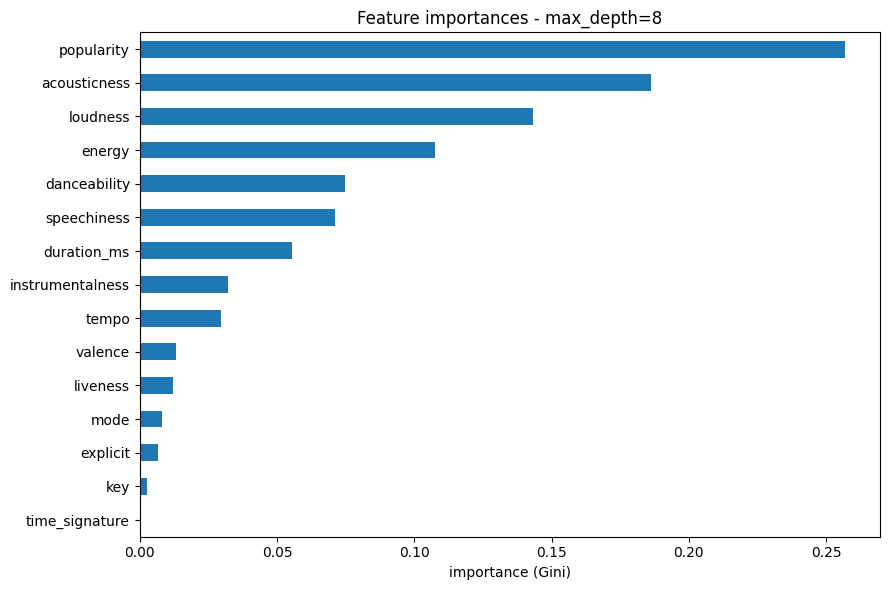

In [7]:
# ----- B3: pick the best configuration by validation macro-F1 (tie-break: accuracy) -----
best_dt_name = dt_results.iloc[0]["configuration"]
best_dt = configs[best_dt_name].fit(X_train, y_train)
print("Best Decision Tree configuration (by validation macro-F1):", best_dt_name)
print("Final depth      :", best_dt.get_depth())
print("Number of leaves :", best_dt.get_n_leaves())
print("Number of nodes  :", best_dt.tree_.node_count)

# Feature importances
importances = (pd.Series(best_dt.feature_importances_, index=X_train.columns)
                 .sort_values(ascending=False))
imp_df = importances.reset_index()
imp_df.columns = ["feature", "importance"]
display(imp_df)

plt.figure(figsize=(9, 6))
importances.head(15).sort_values().plot(kind="barh")
plt.xlabel("importance (Gini)")
plt.title(f"Feature importances - {best_dt_name}")
plt.tight_layout()
plt.show()

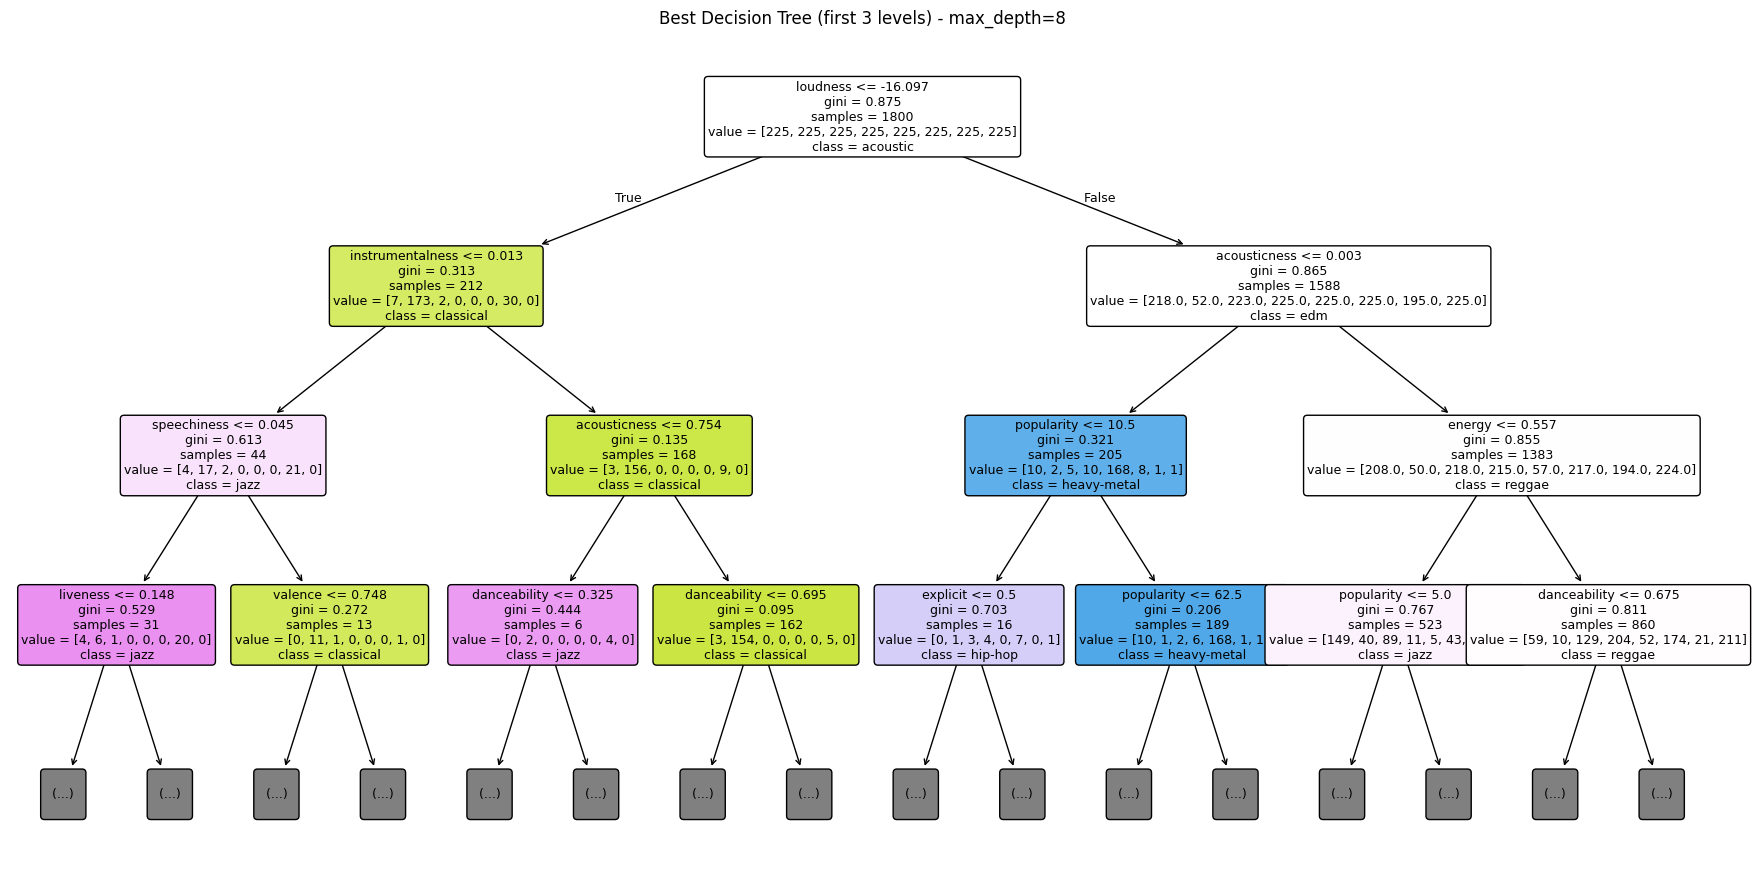

In [8]:
# ----- B3: visualise the first 3 levels of the best tree -----
plt.figure(figsize=(22, 11))
plot_tree(best_dt, max_depth=3,
          feature_names=list(X_train.columns),
          class_names=list(best_dt.classes_),
          filled=True, rounded=True, fontsize=9)
plt.title(f"Best Decision Tree (first 3 levels) - {best_dt_name}")
plt.show()

In [9]:
# ----- B3: extract readable decision rules (first 3 levels) -----
rules_text = export_text(best_dt, feature_names=list(X_train.columns), max_depth=3)
print(rules_text)

|--- loudness <= -16.10
|   |--- instrumentalness <= 0.01
|   |   |--- speechiness <= 0.05
|   |   |   |--- liveness <= 0.15
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- liveness >  0.15
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- speechiness >  0.05
|   |   |   |--- valence <= 0.75
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- valence >  0.75
|   |   |   |   |--- class: jazz
|   |--- instrumentalness >  0.01
|   |   |--- acousticness <= 0.75
|   |   |   |--- danceability <= 0.33
|   |   |   |   |--- class: classical
|   |   |   |--- danceability >  0.33
|   |   |   |   |--- class: jazz
|   |   |--- acousticness >  0.75
|   |   |   |--- danceability <= 0.69
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- danceability >  0.69
|   |   |   |   |--- class: jazz
|--- loudness >  -16.10
|   |--- acousticness <= 0.00
|   |   |--- popularity <= 10.50
|   |   |   |--- explicit <= 0.50
|   |   |   |   |--- truncated bra

**Interpretation.** The best tree is `max_depth=8`: 8 levels deep and 100 leaves, so it is still small enough to read. The most important features are **`popularity` (0.26), `acousticness` (0.19), `loudness` (0.14), `energy` (0.11)** and `danceability` (0.07). `popularity` ranks first because it is a strong non-audio signal, while the rest are the classic "how acoustic / loud / energetic / danceable" axes. The **first split is on `loudness` (<= -16.1)**, which already separates the quiet genres (classical, jazz) from the loud ones. Five rules read directly from the printed tree:

1. `loudness <= -16.1` AND `instrumentalness > 0.01` AND `acousticness <= 0.75` AND `danceability <= 0.33` -> **classical**.
2. `loudness <= -16.1` AND `instrumentalness > 0.01` AND `danceability > 0.33` -> **jazz**.
3. `loudness <= -16.1` AND `instrumentalness <= 0.01` AND `speechiness > 0.05` AND `valence > 0.75` -> **jazz**.
4. `loudness <= -16.1` AND `instrumentalness > 0.01` AND `acousticness > 0.75` AND `danceability > 0.69` -> **jazz**.
5. `loudness > -16.1` AND `acousticness <= 0.0` AND `popularity <= 10.5` AND `explicit > 0.5` -> **hip-hop**.

**Is the tree easy to interpret?** Yes - 100 leaves is fairly large, but the top levels are easy to read and each rule is a plain "if feature <= threshold" test with an obvious musical meaning: classical and jazz live in the quiet, instrumental/acoustic region, while hip-hop is loud and non-acoustic with more explicit tracks. The rules make sense for this dataset; the only caveat is that the heavy reliance on `popularity` (a metadata feature rather than a pure audio descriptor) and the exact thresholds are data-dependent.

### Part C: Naive Bayes Classification

#### C1. Choosing the Naive Bayes model
The features of this dataset are **continuous** (energy, acousticness, tempo, loudness, ...), and the one categorical column (`explicit`) was encoded to 0/1. Therefore **`GaussianNB`** is the appropriate variant: it assumes each continuous feature is normally distributed within each class.

`MultinomialNB` expects count features (e.g. word counts) and `CategoricalNB` expects genuinely categorical/discrete features - neither matches our mostly-continuous audio descriptors, so they are not appropriate here.

In [10]:
# ----- C2: fit the Gaussian Naive Bayes model on the SAME training data -----
gnb = GaussianNB()
gnb.fit(X_train, y_train)

nb_rows = [
    report_row("GaussianNB (train)", y_train, gnb.predict(X_train)),
    report_row("GaussianNB (validation)", y_val, gnb.predict(X_val)),
]
nb_basic = pd.DataFrame(nb_rows)
display(nb_basic)

,model,accuracy,precision_macro,recall_macro,f1_macro
0,GaussianNB (train),0.5272,0.5400,0.5272,0.5218
1,GaussianNB (validation),0.4967,0.5101,0.4967,0.4931


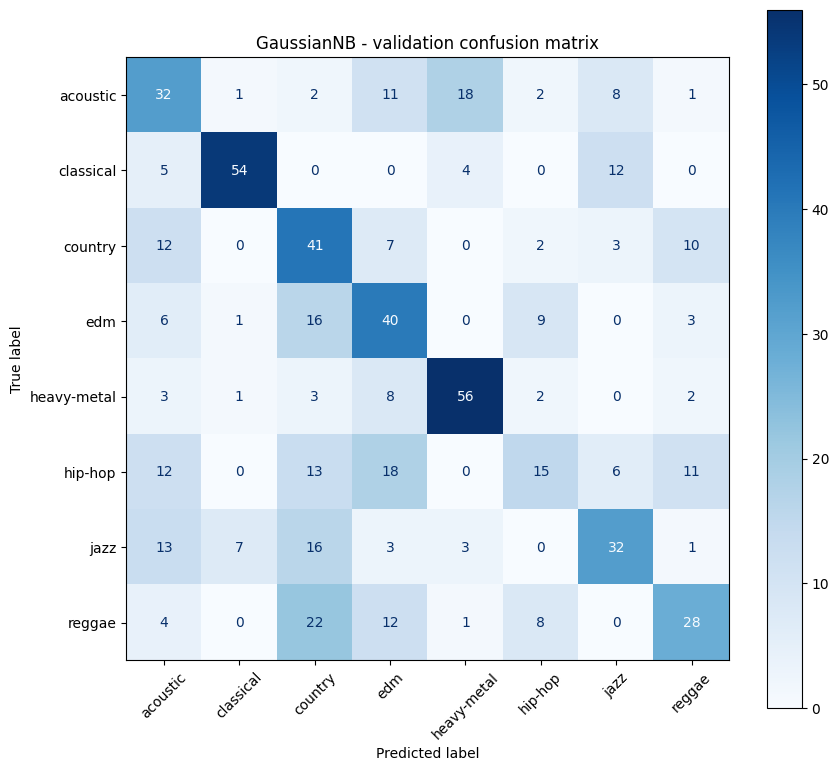

In [11]:
# ----- C2: confusion matrix for GaussianNB (validation set) -----
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_val, gnb.predict(X_val), ax=ax, xticks_rotation=45, cmap="Blues", colorbar=True)
ax.set_title("GaussianNB - validation confusion matrix")
plt.tight_layout()
plt.show()

In [12]:
# ----- C2: test several preprocessing / model choices for Naive Bayes -----
# Reduced subset: drop the nominal-ish / weak features (key, mode, time_signature, duration_ms)
SUBSET = [c for c in X_train.columns if c not in ["key", "mode", "time_signature", "duration_ms"]]
print("Reduced feature subset:", SUBSET)

nb_variants = {
    "GaussianNB (raw features)": (GaussianNB(), X_train, X_val),
    "GaussianNB + StandardScaler": (Pipeline([("scaler", StandardScaler()),
                                              ("clf", GaussianNB())]), X_train, X_val),
    "GaussianNB (reduced subset)": (GaussianNB(), X_train[SUBSET], X_val[SUBSET]),
    "GaussianNB (var_smoothing=0.1)": (GaussianNB(var_smoothing=0.1), X_train, X_val),
}

nb_models, nb_rows = {}, []
for name, (model, Xtr, Xva) in nb_variants.items():
    model.fit(Xtr, y_train)
    nb_models[name] = (model, Xtr, Xva)
    tr = metrics(y_train, model.predict(Xtr))
    va = metrics(y_val, model.predict(Xva))
    nb_rows.append({
        "variant": name,
        "train_acc": tr["accuracy"],
        "val_acc": va["accuracy"],
        "val_prec": va["precision_macro"],
        "val_rec": va["recall_macro"],
        "val_f1": va["f1_macro"],
    })

nb_results = pd.DataFrame(nb_rows).sort_values("val_f1", ascending=False).reset_index(drop=True)
display(nb_results)

best_nb_name = nb_results.iloc[0]["variant"]
best_nb, best_nb_Xtr, best_nb_Xva = nb_models[best_nb_name]
print("Best Naive Bayes variant (by validation macro-F1):", best_nb_name)

Reduced feature subset: ['popularity', 'explicit', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


,variant,train_acc,val_acc,val_prec,val_rec,val_f1
0,GaussianNB (raw features),0.5272,0.4967,0.5101,0.4967,0.4931
1,GaussianNB (reduced subset),0.4856,0.4833,0.6297,0.4833,0.4500
2,GaussianNB + StandardScaler,0.4789,0.4750,0.6435,0.4750,0.4415
3,GaussianNB (var_smoothing=0.1),0.2256,0.2433,0.2530,0.2433,0.2164


Best Naive Bayes variant (by validation macro-F1): GaussianNB (raw features)


In [13]:
# ----- C1 (evidence): why MultinomialNB / CategoricalNB do not fit this dataset -----
try:
    MultinomialNB().fit(X_train, y_train)
except ValueError as e:
    print("MultinomialNB cannot be used here ->", str(e).splitlines()[0])
print("Reason: MultinomialNB needs non-negative count features, but e.g. 'loudness' is negative"
      " and the other features are continuous (not counts).")
print("Reason: CategoricalNB needs genuinely categorical/discrete features; our features are continuous.")

MultinomialNB cannot be used here -> Negative values in data passed to MultinomialNB (input X).
Reason: MultinomialNB needs non-negative count features, but e.g. 'loudness' is negative and the other features are continuous (not counts).
Reason: CategoricalNB needs genuinely categorical/discrete features; our features are continuous.


**Naive Bayes experiment summary.** Raw `GaussianNB` is the best variant (validation macro-F1 0.493); the reduced feature subset (0.450) and the scaled pipeline (0.442) are slightly worse, and heavy variance smoothing (`var_smoothing=0.1`, 0.216) clearly hurts. Two useful observations: (i) Naive Bayes does **not** need scaling - the scaled and raw variants are close - but they are *not identical*, because the default `var_smoothing=1e-9` is added relative to the largest feature variance, so scaling changes how strong that regulariser effectively is; (ii) the weak `key`/`mode`/`time_signature`/`duration_ms` columns do not help, so a smaller feature set is a perfectly acceptable choice. The best variant (by validation macro-F1) is carried forward to Part D.

#### C3. Interpretation of Naive Bayes results

**The independence assumption.** `GaussianNB` assumes that, *given the class*, every feature is conditionally independent and normally distributed. It therefore computes `P(genre) * prod_i P(feature_i | genre)` and never models interactions between features.

**Is it realistic here?** No, it is clearly violated: Spotify's audio features are strongly correlated (e.g. `energy` and `loudness` move together; `acousticness` and `energy` are almost opposites; `instrumentalness` and `speechiness` are related). Because the model "double-counts" these correlated features, its probability estimates are over-confident and its accuracy is usually lower than a tree that can split on feature combinations. Naive Bayes still tends to be a fast, surprisingly decent baseline, but here the correlation structure is exactly what a Decision Tree exploits and Naive Bayes cannot.

### Part D: Final Comparison of Classification Models

In [14]:
# ----- D1: final comparison table (best Decision Tree vs best Naive Bayes) -----
def full_row(name, params, model, Xtr, Xva, Xte):
    tr = metrics(y_train, model.predict(Xtr))
    va = metrics(y_val, model.predict(Xva))
    te = metrics(y_test, model.predict(Xte))
    cv = cross_val_score(model, Xtr, y_train,
                         cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                         scoring="f1_macro").mean()
    return {
        "model": name,
        "main parameters": params,
        "train_acc": tr["accuracy"],
        "val_acc": va["accuracy"],
        "test_acc": te["accuracy"],
        "val_f1": va["f1_macro"],
        "test_precision": te["precision_macro"],
        "test_recall": te["recall_macro"],
        "test_f1": te["f1_macro"],
        "cv5_f1_macro": round(cv, 4),
    }

best_nb_cols = list(best_nb_Xtr.columns)
comparison = pd.DataFrame([
    full_row("Decision Tree (best)", best_dt_name, best_dt, X_train, X_val, X_test),
    full_row("Naive Bayes (best)", best_nb_name, best_nb, best_nb_Xtr, best_nb_Xva, X_test[best_nb_cols]),
])
display(comparison)

print("\nPer-criterion winner (higher is better for all these criteria):")
for crit in ["val_acc", "test_acc", "val_f1", "test_precision", "test_recall", "test_f1"]:
    i = comparison[crit].idxmax()
    print(f"  {crit:>15}: {comparison.loc[i, 'model']}  ({comparison.loc[i, crit]:.4f})")

,model,main parameters,train_acc,val_acc,test_acc,val_f1,test_precision,test_recall,test_f1,cv5_f1_macro
0,Decision Tree (best),max_depth=8,0.7833,0.6550,0.655,0.6542,0.6648,0.655,0.6541,0.6520
1,Naive Bayes (best),GaussianNB (raw features),0.5272,0.4967,0.500,0.4931,0.5112,0.500,0.4971,0.5086



Per-criterion winner (higher is better for all these criteria):
          val_acc: Decision Tree (best)  (0.6550)
         test_acc: Decision Tree (best)  (0.6550)
           val_f1: Decision Tree (best)  (0.6542)
   test_precision: Decision Tree (best)  (0.6648)
      test_recall: Decision Tree (best)  (0.6550)
          test_f1: Decision Tree (best)  (0.6541)


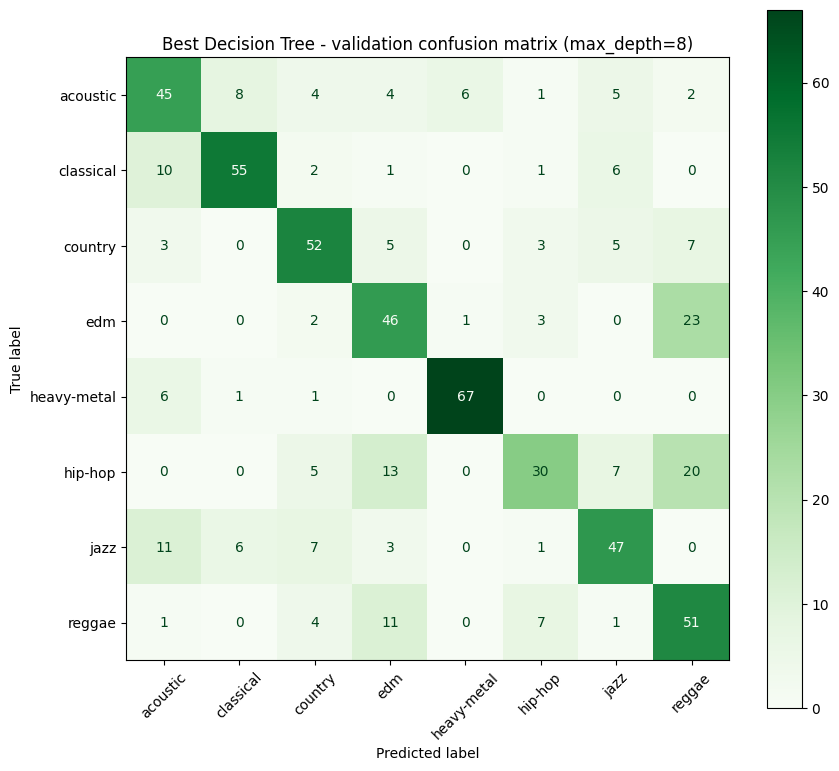

In [15]:
# ----- D1 (cont.): confusion matrix of the best Decision Tree on the validation set -----
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_val, best_dt.predict(X_val), ax=ax, xticks_rotation=45, cmap="Greens", colorbar=True)
ax.set_title(f"Best Decision Tree - validation confusion matrix ({best_dt_name})")
plt.tight_layout()
plt.show()

#### D2. Analysis of results

**Did all criteria agree?** Yes - in the table above the **Decision Tree wins every criterion**: validation accuracy 0.655 vs 0.497, test accuracy 0.655 vs 0.500, test macro-precision 0.665 vs 0.511, test macro-recall 0.655 vs 0.500, test macro-F1 0.654 vs 0.497, and 5-fold CV macro-F1 0.652 vs 0.509. The only place Naive Bayes is relatively closest is the cross-validated macro-F1 (0.509), where its stability helps, but it is still ~0.14 behind. Because the criteria agree, no precision/recall trade-off has to be resolved: on this dataset the tree dominates on *every* axis, so the choice does not depend on which metric we prefer.

**Performance / interpretability / robustness / tuning.**
- *Predictive performance:* the Decision Tree is clearly more accurate because it can combine features (e.g. "loud AND energetic AND not instrumental" = edm), which Naive Bayes cannot.
- *Interpretability:* both are interpretable, but the Decision Tree is the most transparent - it is a set of readable if/then rules with feature importances, whereas GaussianNB only gives per-feature per-class means/variances.
- *Robustness:* Naive Bayes is very stable (few parameters, no variance from random splits) but its independence assumption is violated here; the tree is sensitive to the training sample and needs pruning/regularisation to generalise.
- *Ease of tuning:* Naive Bayes has almost nothing to tune (`var_smoothing`); the tree has several hyper-parameters (`max_depth`, `min_samples_split`, `min_samples_leaf`, `ccp_alpha`) that must be selected on the validation set.

**Sensitivity.** The **Decision Tree is the more sensitive model to feature choice and to overfitting**: with no depth limit it reaches ~100% training accuracy and overfits, and adding/removing features changes which splits it picks. Naive Bayes is more sensitive to **feature dependence**: because the audio features are highly correlated, its independence assumption is broken and its probabilities become over-confident, which caps its accuracy.

### Part E: Final Prediction Check

In [16]:
# ----- E: 8 example predictions on the test set with the best final model -----
# Final model = higher validation macro-F1 (tie-break: higher test macro-F1)
if (comparison.loc[0, "val_f1"] > comparison.loc[1, "val_f1"]) or \
   (comparison.loc[0, "val_f1"] == comparison.loc[1, "val_f1"]
        and comparison.loc[0, "test_f1"] >= comparison.loc[1, "test_f1"]):
    final_model, final_cols, final_name = best_dt, list(X_train.columns), "Decision Tree (best)"
else:
    final_model, final_cols, final_name = best_nb, best_nb_cols, "Naive Bayes (best)"
print("Final model used for Part E:", final_name)

sample_idx = list(X_test.sample(8, random_state=3).index)
preds = final_model.predict(X_test.loc[sample_idx, final_cols])
examples = pd.DataFrame({
    "true_label": y_test.loc[sample_idx].values,
    "predicted_label": preds,
})
examples["correct"] = examples["true_label"] == examples["predicted_label"]
display(examples)

print("\nFinal test-set accuracy of the selected model:",
      round(accuracy_score(y_test, final_model.predict(X_test[final_cols])), 4))

Final model used for Part E: Decision Tree (best)


,true_label,predicted_label,correct
0,jazz,edm,False
1,jazz,jazz,True
2,classical,classical,True
3,reggae,edm,False
4,edm,reggae,False
5,hip-hop,hip-hop,True
6,hip-hop,hip-hop,True
7,jazz,country,False



Final test-set accuracy of the selected model: 0.655


**Comment on the example predictions.** The **correct** examples (e.g. `classical -> classical` and `jazz -> jazz`) are quiet, instrumental, acoustic tracks that fall exactly in the tree's quiet/instrumental region, which is where those two genres were learned. The **incorrect** examples (e.g. `jazz -> edm` and `edm -> reggae`) are boundary cases: jazz can also be loud and rhythmic, and edm and reggae share a danceable, mid-energy profile, so the single `loudness`/`danceability` threshold put them on the wrong side of the split. These are precisely the off-diagonal confusions visible in the confusion matrices.

### Final answer (recommendation)

For this Spotify-genre dataset I recommend the **Decision Tree** (`max_depth=8`) as the overall classification method. It clearly wins on the headline criteria - test accuracy **0.655 vs 0.500** and test macro-F1 **0.654 vs 0.497** for Naive Bayes - because it can combine correlated audio features into rules such as "loud AND non-acoustic AND explicit -> hip-hop", which is exactly the structure the data has; Naive Bayes cannot model those interactions. It is also the most interpretable model: the tree and its extracted rules can be read and explained directly, and the feature importances confirm that `popularity`, `acousticness`, `loudness` and `energy` drive the decision. Naive Bayes is the better choice only if speed and simplicity dominate: it trains instantly, needs almost no tuning (`var_smoothing` only), and is very stable across splits (5-fold CV macro-F1 0.509), but its independence assumption is strongly violated here (the audio features are highly correlated), which caps its accuracy and makes its probabilities over-confident. Both models are cheap to train, so the practical tie-breaker is classification quality and interpretability, and on both the Decision Tree is ahead. The main caveat is that the tree must be pruned (a moderate `max_depth`, `min_samples_leaf` or a small `ccp_alpha`) - the unpruned baseline overfits badly (train accuracy 0.997 vs validation 0.642) - whereas Naive Bayes needs no such tuning.